# 04 — Análisis exploratorio de fraude (EDA)

## ¿Qué voy a hacer en este notebook?

En el notebook 02 comprobé que el fraude es poco frecuente, pero económicamente relevante. Ahora voy a profundizar en **dónde** y **cómo** aparece para encontrar señales que después puedan apoyar un modelo o una regla de alerta.

Mi recorrido será:

1. Comparar el fraude por **tipo** de transacción.  
2. Separar las operaciones por **rangos de monto**.  
3. Revisar **saldos** para buscar señales de vaciamiento o inconsistencias.  
4. Evaluar qué tan útil fue la alerta existente `isFlaggedFraud`.

> Ejecutaré con `USE_SAMPLE = False` para obtener las conclusiones del dataset completo. Si activo una muestra, debo volver a interpretar los números obtenidos.

In [1]:
from pathlib import Path

# Rutas del proyecto (ejecutar notebooks desde la carpeta notebooks/)
PROJECT_ROOT = Path('..').resolve()
DATA_RAW = PROJECT_ROOT / 'data' / 'raw' / 'paysim.csv'
IMAGES_DIR = PROJECT_ROOT / 'images'
REPORTS_DIR = PROJECT_ROOT / 'reports'

IMAGES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

USE_SAMPLE = False
SAMPLE_FRAC = 0.05  # 5% estratificado por fraude si USE_SAMPLE es True
RANDOM_STATE = 42


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

if not DATA_RAW.exists():
    raise FileNotFoundError(
        f'No encontré el dataset en {DATA_RAW}. '
        'Verifica el enlace simbólico data/raw/paysim.csv'
    )

# Tipos optimizados para ahorrar memoria
dtype_map = {
    'type': 'category',
    'nameOrig': 'string',
    'nameDest': 'string',
    'isFraud': 'int8',
    'isFlaggedFraud': 'int8',
}

print('Cargando datos... (puede tardar unos minutos)')
df = pd.read_csv(DATA_RAW, dtype=dtype_map)

if USE_SAMPLE:
    # Muestra estratificada: conserva la proporción de fraude del dataset completo
    fraud = df[df['isFraud'] == 1]
    legit = df[df['isFraud'] == 0]
    n_fraud = max(1, int(len(fraud) * SAMPLE_FRAC))
    n_legit = int(len(legit) * SAMPLE_FRAC)
    df = pd.concat([
        fraud.sample(n=min(n_fraud, len(fraud)), random_state=RANDOM_STATE),
        legit.sample(n=min(n_legit, len(legit)), random_state=RANDOM_STATE),
    ]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    print(f'Modo muestra activado: {len(df):,} filas')

print(f'Filas: {len(df):,} | Columnas: {df.shape[1]}')
df.head()


Cargando datos... (puede tardar unos minutos)
Filas: 6,362,620 | Columnas: 11


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


---
## Sección 3 — Análisis por tipo de transacción

### Qué voy a calcular

Agrupo las transacciones por `type` y, para cada tipo, calculo cuántas operaciones tiene, cuántas son fraude, cuánto dinero fraudulento mueve y cuál es su tasa de fraude. Así respondo tres preguntas:

- ¿Qué tipo concentra más fraudes en cantidad?
- ¿Qué tipo mueve más dinero fraudulento?
- ¿Cambia la tasa de fraude según el tipo?

La tabla me entrega el dato exacto y los gráficos facilitan la comparación visual.

In [8]:
by_type = df.groupby('type', observed=True).agg( #La tabla y los agrupamos por los tipos de transacción
    transacciones=('isFraud', 'size'), #esta tabla se le agrega el tamaño total de transacciones por cada tipo
    fraudes=('isFraud', 'sum'), #el total de fraudes por cada tipo
    monto_total=('amount', 'sum'), #la suma o total de moton por cada tipo
)
monto_fraude_tipo = df.loc[df['isFraud'] == 1].groupby('type', observed=True)['amount'].sum() #se filtra para todos ldonde si hubo fraude (osea isFraud = 1) y sumamos el total del monto agrupado por el tipo 
                                                                                              #Se hace asi para luego crear las columnas monto total de fraude por tipo, la tasa x fraude, etc.              
by_type['monto_fraude'] = monto_fraude_tipo.reindex(by_type.index, fill_value=0) #monto total fraude x tipo de transaccion
by_type['tasa_fraude_pct'] = (by_type['fraudes'] / by_type['transacciones'] * 100).round(4) # porcentaje de fraude x transacciones
by_type['monto_prom_fraude'] = by_type['monto_fraude'] / by_type['fraudes'].replace(0, np.nan)

by_type.sort_values('fraudes', ascending=False) #Lo ordenamos por la columna fraudes de mayor a menor

,transacciones,fraudes,monto_total,monto_fraude,tasa_fraude_pct,monto_prom_fraude
type,,,,,,
CASH_OUT,2237500,4116,3.944130e+11,5.989202e+09,0.1840,1.455103e+06
TRANSFER,532909,4097,4.852920e+11,6.067213e+09,0.7688,1.480892e+06
CASH_IN,1399284,0,2.363674e+11,0.000000e+00,0.0000,NaN
DEBIT,41432,0,2.271992e+08,0.000000e+00,0.0000,NaN
PAYMENT,2151495,0,2.809337e+10,0.000000e+00,0.0000,NaN


- TRANSFER: 4097 fraudes — monto fraudulento: 6,067,213,184.01
- CASH_OUT: 4116 fraudes — monto fraudulento: 5,989,202,243.83

##### Por qué ocurre en estos tipos:

- TRANSFER y CASH_OUT implican extracción de fondos desde la cuenta origen (transferencias entre cuentas y retiros), lo que facilita el vaciamiento y la extracción por atacantes.
- Ambos presentan tasas y montos fraudulentos altos y con frecuencia dejan el saldo origen en cero, patrón consistente con conductas maliciosas.

##### Por qué no se observan fraudes en otros tipos (CASH_IN, PAYMENT, DEBIT):

- CASH_IN representa ingresos a la cuenta (recargas), no permite vaciamiento inmediato.
- PAYMENT son pagos a comercios, con controles y flujo que dificultan la extracción directa.
- DEBIT tiene muy pocos registros y no muestra evidencia de patrones fraudulentos en este dataset.

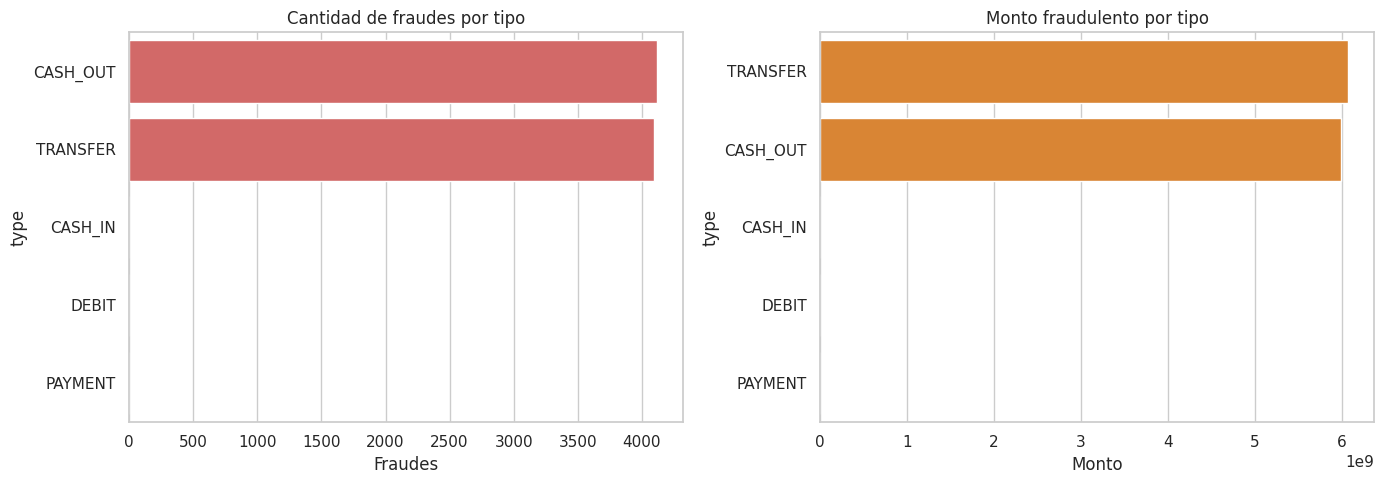

Guardado: /home/johanrobles/Documentos/Idea/analisis-fraude-&-modelo-predictivo-datasetPaySim/images/fraud_by_type.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = by_type.sort_values('fraudes', ascending=False).index
sns.barplot(x=by_type.loc[order, 'fraudes'], y=order.astype(str), ax=axes[0], color='#e45756')
axes[0].set_title('Cantidad de fraudes por tipo')
axes[0].set_xlabel('Fraudes')

order2 = by_type.sort_values('monto_fraude', ascending=False).index
sns.barplot(x=by_type.loc[order2, 'monto_fraude'], y=order2.astype(str), ax=axes[1], color='#f58518')
axes[1].set_title('Monto fraudulento por tipo')
axes[1].set_xlabel('Monto')

plt.tight_layout()
out = IMAGES_DIR / 'fraud_by_type.png'
plt.savefig(out, bbox_inches='tight')
plt.show()
print('Guardado:', out)

### Conclusión por tipo de transacción

Al analizar el dataset completo observo que los fraudes aparecen únicamente en **`CASH_OUT`** (4.116 casos) y **`TRANSFER`** (4.097 casos). Aunque `CASH_OUT` tiene ligeramente más casos, `TRANSFER` mueve más dinero fraudulento (aproximadamente **6.067 millones**) y presenta la tasa más alta (**0,7688%**, frente a **0,1840%** en `CASH_OUT`).

Mi conclusión es que una estrategia de monitoreo debe priorizar especialmente las transferencias y los retiros de efectivo; no tiene sentido tratar todos los tipos de operación como si tuvieran el mismo riesgo.

---
## Sección 4 — Análisis por monto

### Qué voy a calcular

Quiero comprobar si el valor de la operación ayuda a diferenciar el riesgo. Para hacerlo, divido `amount` en cinco rangos y calculo cantidad de fraudes, monto fraudulento y tasa de fraude en cada rango. Además uso una escala logarítmica para visualizar montos pequeños y grandes en un mismo gráfico.

In [10]:
bins = [0, 10_000, 100_000, 500_000, 1_000_000, np.inf] #rangos
labels = ['0-10k', '10k-100k', '100k-500k', '500k-1M', '>1M'] #los rangos para las filas

# Crear columna categórica 'amount_range' partiendo 'amount' en los bins definidos
# (intervalos cerrados por la derecha: cada intervalo incluye su extremo superior)
df['amount_range'] = pd.cut(df['amount'], bins=bins, labels=labels, right=True) #notemos que estamos haicneod un cut (corte) sobre la columna monto segun los bins la los valores de la lista bins

# Agrupar transacciones por rango de monto
# Calcula cantidad total de transacciones y fraudes en cada rango
by_range = df.groupby('amount_range', observed=False).agg( #ya le agregamos el rango por moton, en la cusl se rango va segun la lisya bins
    transacciones=('isFraud', 'size'),  # Total de transacciones por rango
    fraudes=('isFraud', 'sum'),  # Total de fraudes por rango
)
monto_fraude_rango = df.loc[df['isFraud'] == 1].groupby('amount_range', observed=False)['amount'].sum() #la suma de todas las transacciones fraudalentas segun los rangos
by_range['monto_fraude'] = monto_fraude_rango.fillna(0) #la columna monton fraude que indica el total de fruades x transaccion segun rango, en la que en dado caso haya un valo indefinido (NaN) como resultado de la suma lo llena como 0
by_range['tasa_fraude_pct'] = (by_range['fraudes'] / by_range['transacciones'] * 100).round(4) #porcentaje de tasa de fraudes x rango de transaccion

by_range

,transacciones,fraudes,monto_fraude,tasa_fraude_pct
amount_range,,,,
0-10k,1286075,262,1.201826e+06,0.0204
10k-100k,2239207,1429,7.181823e+07,0.0638
100k-500k,2497038,2642,6.813699e+08,0.1058
500k-1M,209658,1158,8.413032e+08,0.5523
>1M,130626,2706,1.046072e+10,2.0716


Vemos algo interesante, donde comeinza a haber mas fruades segun el rango es a partir del monto 100k, pues podemos ver que la tasa va aimentando, siendo el rango de monton de mas de 1m el que se nota la mayor tasa.

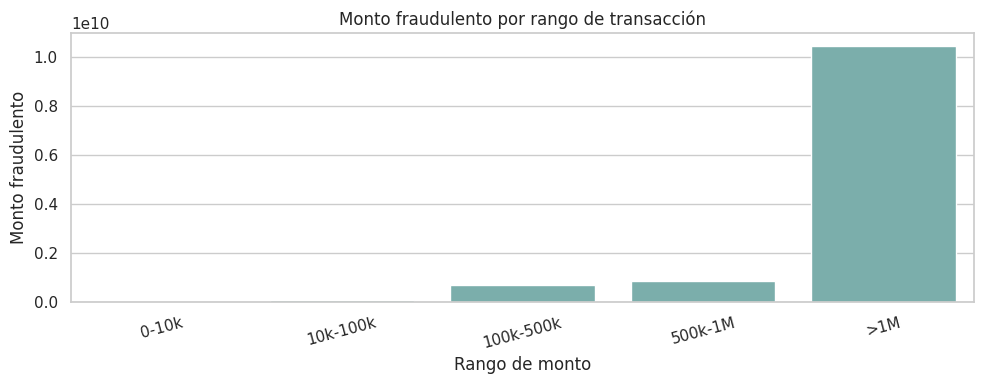

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=by_range.reset_index(), x='amount_range', y='monto_fraude', ax=ax, color='#72b7b2')
ax.set_title('Monto fraudulento por rango de transacción')
ax.set_xlabel('Rango de monto')
ax.set_ylabel('Monto fraudulento')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'fraud_by_amount_range.png', bbox_inches='tight')
plt.show()

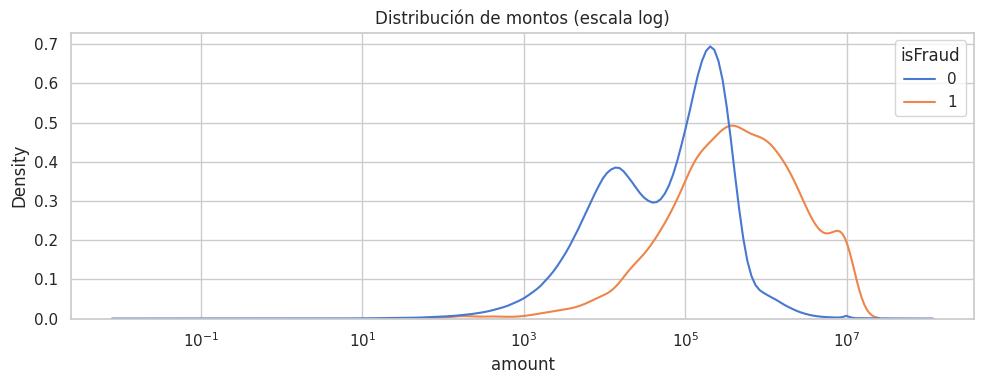

In [12]:
# Comparación de montos positivos: la escala logarítmica no admite valores en cero.
positive_amounts = df.loc[df['amount'] > 0, ['amount', 'isFraud']]
fig, ax = plt.subplots(figsize=(10, 4))
sns.kdeplot(data=positive_amounts, x='amount', hue='isFraud', log_scale=True, ax=ax, common_norm=False, warn_singular=False)
ax.set_title('Distribución de montos (escala log)')
plt.tight_layout()
plt.show()

### Conclusión por monto

El rango de más de **1.000.000** contiene **2.706 fraudes**, una tasa de **2,0716%** y aproximadamente **10.460 millones** en monto fraudulento. Esta concentración es mucho mayor que en los rangos bajos. Por eso concluyo que `amount` sí es una señal importante, aunque no debería usarse sola: un monto alto debe combinarse con el tipo de operación y el comportamiento de saldos.

---
## Sección 5 — Análisis de saldos

### Qué voy a calcular

Ahora reviso qué ocurre con el dinero antes y después de la transacción. Creo variables que me ayudan a expresar comportamientos que serían sospechosos en un contexto bancario:

- `origin_balance_diff` = saldo que sale de la cuenta origen.  
- `balance_error_origin` = diferencia entre el saldo esperado y el saldo reportado después del movimiento.  
- `is_origin_balance_zero` = indicador de si la cuenta origen quedó en cero, posible señal de vaciamiento.

Comparo estas señales entre fraude y no fraude para saber si vale la pena considerarlas en la siguiente fase.

In [13]:
df['origin_balance_diff'] = df['oldbalanceOrg'] - df['newbalanceOrig']
df['dest_balance_diff'] = df['newbalanceDest'] - df['oldbalanceDest']
df['balance_error_origin'] = df['oldbalanceOrg'] - df['amount'] - df['newbalanceOrig']
df['balance_error_dest'] = df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']
df['is_origin_balance_zero'] = (df['newbalanceOrig'] == 0).astype('int8')

fraud = df['isFraud'] == 1
legit = df['isFraud'] == 0

balance_kpis = pd.Series({
    '% fraude con saldo origen en cero': round(df.loc[fraud, 'is_origin_balance_zero'].mean() * 100, 2),
    '% no fraude con saldo origen en cero': round(df.loc[legit, 'is_origin_balance_zero'].mean() * 100, 2),
    'Error balance origen (promedio |error| fraude)': df.loc[fraud, 'balance_error_origin'].abs().mean(),
    'Error balance origen (promedio |error| no fraude)': df.loc[legit, 'balance_error_origin'].abs().mean(),
    'Transacciones con |error origen| > 1': int((df['balance_error_origin'].abs() > 1).sum()),
})

balance_kpis

% fraude con saldo origen en cero                    9.805000e+01
% no fraude con saldo origen en cero                 5.668000e+01
Error balance origen (promedio |error| fraude)       1.069233e+04
Error balance origen (promedio |error| no fraude)    2.013386e+05
Transacciones con |error origen| > 1                 5.000784e+06
dtype: float64

### Conclusión sobre saldos

Encuentro que **98,05%** de las transacciones fraudulentas dejan el saldo de origen en cero, mientras que esto ocurre en **56,68%** de las no fraudulentas. El vaciamiento es una señal relevante, pero no constituye una prueba por sí sola porque también aparece en operaciones legítimas. Por eso usaré esta variable como candidata junto con monto y tipo, no como una regla aislada.

---
## Sección 6 — Análisis de alertas (`isFlaggedFraud`)

### Qué voy a calcular

Finalmente comparo la etiqueta real `isFraud` contra la alerta original `isFlaggedFraud`. Esta comparación me permite medir si el sistema existente estaba detectando los casos que realmente ocurrieron y, especialmente, cuánto dinero fraudulento dejó pasar.

| isFraud | isFlaggedFraud | Interpretación |
|---------|----------------|----------------|
| 1 | 1 | Fraude detectado por el sistema |
| 1 | 0 | **Fraude no detectado** (riesgo crítico) |
| 0 | 1 | Posible falsa alerta |
| 0 | 0 | Transacción normal |

In [ ]:
# Crea una columna categórica que clasifica cada transacción según fraude real y alerta
df['alert_case'] = np.select(
    [
        (df['isFraud'] == 1) & (df['isFlaggedFraud'] == 1),  # Fraude real Y alertado
        (df['isFraud'] == 1) & (df['isFlaggedFraud'] == 0),  # Fraude real PERO no alertado
        (df['isFraud'] == 0) & (df['isFlaggedFraud'] == 1),  # No fraude PERO alertado (falsa alerta)
    ],
    ['Fraude detectado', 'Fraude NO detectado', 'Posible falsa alerta'],  # Etiquetas correspondientes
    default='Normal',  # Categoría por defecto para el resto
)

# Agrupa por categoría de alerta y calcula cantidad de transacciones y monto total
alert_summary = df.groupby('alert_case').agg(
    transacciones=('amount', 'size'),  # Cuenta de transacciones por categoría
    monto_total=('amount', 'sum'),  # Suma de montos por categoría
).sort_values('transacciones', ascending=False)  # Ordena de mayor a menor cantidad

# Calcula el monto total de fraude real (independiente de si fue detectado)
fraud_total = df.loc[df['isFraud'] == 1, 'amount'].sum()

# Calcula el monto de fraude que SÍ fue detectado por el sistema
detected_amt = df.loc[(df['isFraud'] == 1) & (df['isFlaggedFraud'] == 1), 'amount'].sum()

# Calcula el monto de fraude que NO fue detectado (dejó pasar)
undetected_amt = df.loc[(df['isFraud'] == 1) & (df['isFlaggedFraud'] == 0), 'amount'].sum()

# Calcula la tasa de detección: qué proporción de fraudes reales fueron alertados
detection_rate = df.loc[df['isFraud'] == 1, 'isFlaggedFraud'].mean()

# Crea una serie con métricas clave del desempeño del sistema de alertas
alert_kpis = pd.Series({
    'Fraudes detectados (conteo)': int(((df['isFraud'] == 1) & (df['isFlaggedFraud'] == 1)).sum()),
    'Fraudes NO detectados (conteo)': int(((df['isFraud'] == 1) & (df['isFlaggedFraud'] == 0)).sum()),
    'Monto fraude detectado': detected_amt,
    'Monto fraude NO detectado': undetected_amt,
    'Tasa detección del sistema (%)': round(detection_rate * 100, 4),
})

print(alert_summary)  # Muestra el resumen agrupado
print('\n--- KPIs alertas ---')
print(alert_kpis.to_string())  # Muestra los KPIs formateados

                     transacciones   monto_total
alert_case                                      
Normal                     6354407  1.132337e+12
Fraude NO detectado           8197  1.197863e+10
Fraude detectado                16  7.778556e+07

--- KPIs alertas ---
Fraudes detectados (conteo)       1.600000e+01
Fraudes NO detectados (conteo)    8.197000e+03
Monto fraude detectado            7.778556e+07
Monto fraude NO detectado         1.197863e+10
Tasa detección del sistema (%)    1.948000e-01


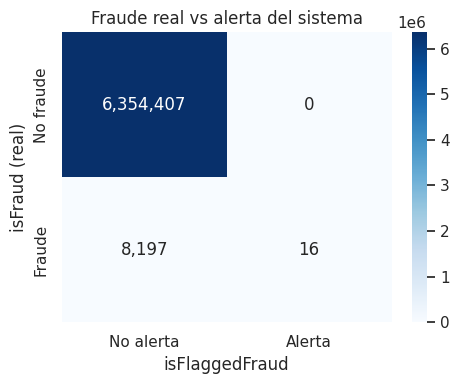

Guardado: /home/johanrobles/Documentos/Idea/analisis-fraude-&-modelo-predictivo-datasetPaySim/images/confusion_matrix.png


In [15]:
# Matriz de confusión simple: fraude real vs alerta (sin sklearn)
cm = pd.crosstab(df['isFraud'], df['isFlaggedFraud']).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=ax,
            xticklabels=['No alerta', 'Alerta'],
            yticklabels=['No fraude', 'Fraude'])
ax.set_xlabel('isFlaggedFraud')
ax.set_ylabel('isFraud (real)')
ax.set_title('Fraude real vs alerta del sistema')
plt.tight_layout()
out = IMAGES_DIR / 'confusion_matrix.png'
plt.savefig(out, bbox_inches='tight')
plt.show()
print('Guardado:', out)

### Conclusión sobre las alertas existentes

La señal `isFlaggedFraud` solo marca **16 de los 8.213 fraudes reales**, es decir, una detección de aproximadamente **0,1948%**. Además, quedan sin marcar **8.197 fraudes** por un monto aproximado de **11.978 millones**. Concluyo que la alerta existente no es suficiente para priorizar riesgo y que se justifica construir una alternativa predictiva.

---
## Variables candidatas para la Parte 2 (modelado)

Después de este EDA, conservaré como candidatas:

- `type`, porque el fraude se concentra en `TRANSFER` y `CASH_OUT`.
- `amount` y rangos de monto, porque la exposición aumenta con operaciones mayores a 1M.
- `origin_balance_diff`, `balance_error_origin` e `is_origin_balance_zero`, porque ayudan a describir el comportamiento del saldo.
- Posibles ratios y banderas de monto alto que combinen más de una señal.

## Conclusión general de la Parte 1

En esta etapa comprobé que no basta con decir que el fraude representa una porción pequeña del dataset. Los casos fraudulentos se concentran en tipos concretos, tienen fuerte exposición en montos altos, muestran con frecuencia vaciamiento del saldo origen y casi nunca fueron marcados por la alerta existente. Con estas conclusiones ya tengo una justificación clara para pasar a la Parte 2: construir variables y evaluar un modelo que priorice mejor las operaciones sospechosas.

In [19]:
# Exporto las tablas y una interpretación breve para conservar el resultado fuera del notebook.
report_path = REPORTS_DIR / 'fraud_analytics_report.md'
top_rate_type = by_type['tasa_fraude_pct'].idxmax()
top_amount_range = by_range['monto_fraude'].idxmax()
content = '\n'.join([
    '# Reporte de análisis de fraude — PaySim (Parte 1)',
    '',
    '> Este reporte se genera al ejecutar `04_exploratory_data_analysis.ipynb`.',
    '',
    '## Conclusiones del análisis',
    '',
    f'- Encontré que el tipo con mayor tasa de fraude es `{top_rate_type}` ({by_type.loc[top_rate_type, "tasa_fraude_pct"]:.4f}%).',
    f'- Observé que el rango con mayor monto fraudulento es `{top_amount_range}` ({by_range.loc[top_amount_range, "monto_fraude"]:,.2f}).',
    f'- Al evaluar la alerta existente, vi que detectó {alert_kpis["Fraudes detectados (conteo)"]:.0f} fraudes y dejó {alert_kpis["Fraudes NO detectados (conteo)"]:.0f} sin marcar.',
    '',
    '## KPIs de alertas',
    alert_kpis.to_string(),
    '',
    '## KPIs de saldos',
    balance_kpis.to_string(),
    '',
    '## Resumen por tipo de transacción',
    by_type.sort_values('fraudes', ascending=False).to_string(),
    '',
    '## Resumen por rango de monto',
    by_range.to_string(),
])
report_path.write_text(content, encoding='utf-8')
print('Reporte actualizado:', report_path)

Reporte actualizado: /home/johanrobles/Documentos/Idea/analisis-fraude-&-modelo-predictivo-datasetPaySim/reports/fraud_analytics_report.md
